# Lab 7 — Sentiment Analysis with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Completed and corrected notebook

**Objective:** Classify an IMDB movie review as **positive (1)** or **negative (0)**.

Pipeline: review text → integer word IDs → padding → Embedding → Bidirectional LSTM → Dropout → sigmoid prediction.

**How to run:** Open this notebook in Google Colab or Jupyter and run all cells from top to bottom. TensorFlow may need to download the IMDB dataset the first time. A GPU is helpful but not compulsory.

**Corrections included:** all student blanks are completed; the model input shape is explicit; prediction preprocessing handles unknown/rare words correctly and uses the IMDB start token; plotting and evaluation are complete.


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split

# Reproducibility (results can still vary slightly across hardware / TensorFlow versions)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## Task 1 — Load and prepare the data

The IMDB dataset is already encoded as integer word IDs; it does not initially contain raw review sentences.

- `num_words = 10000`: keep the 10,000 most frequent words.
- `maxlen = 200`: make every review exactly 200 tokens long.
- Padding adds zeros to short reviews; long reviews are truncated.


In [2]:
# Q1a) Hyperparameters
num_words = 10000
maxlen = 200

# Load 25,000 training reviews and 25,000 test reviews.
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) Pad both sets to a fixed length of 200.
X_train = pad_sequences(X_train, maxlen=maxlen, padding="pre", truncating="pre")
X_test  = pad_sequences(X_test,  maxlen=maxlen, padding="pre", truncating="pre")

# Q1c) Keep 20% of the original training data for validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("y_train labels:", np.unique(y_train))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (20000, 200)
X_val:   (5000, 200)
X_test:  (25000, 200)
y_train labels: [0 1]


#### Quick check *(given)*

In [3]:
# Sanity checks
assert X_train.shape == (20000, 200)
assert X_val.shape == (5000, 200)
assert X_test.shape == (25000, 200)
assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_val)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})

print("Data preparation looks correct.")


Data preparation looks correct.


## Task 2 — Build the Bidirectional LSTM model

Architecture:

1. **Embedding:** turns each word ID into a trainable vector of 128 numbers.
2. **Bidirectional LSTM(64):** reads the review from left-to-right and right-to-left. The two 64-unit outputs are concatenated, giving 128 features.
3. **Dropout(0.5):** randomly drops half the features during training to help reduce overfitting.
4. **Dense(1, sigmoid):** outputs the probability that the review is positive.


In [4]:
model = Sequential(name="IMDB_Bidirectional_LSTM")
model.add(Input(shape=(maxlen,), name="review_tokens"))

# Q2a) Word index -> 128-dimensional trainable embedding vector
model.add(Embedding(input_dim=num_words, output_dim=128, name="word_embedding"))

# Q2b) 64 units in each direction; concatenate forward and backward summaries
model.add(Bidirectional(
    LSTM(64, return_sequences=False),
    name="bidirectional_lstm"
))

# Q2c) Regularisation to reduce overfitting
model.add(Dropout(0.5, name="dropout"))

# Q2d) One output neuron for binary classification
model.add(Dense(1, activation="sigmoid", name="sentiment_output"))

model.summary()


Model: "IMDB_Bidirectional_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm              │ (None, 128)            │        98,816 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

### Reflection — Embedding parameters

The embedding table contains:

`10,000 words × 128 numbers per word = 1,280,000 trainable parameters`.

It has most of the parameters because it stores one 128-number vector for each of the 10,000 vocabulary entries.


## Task 3 — Compile and train

- **Adam:** optimizer that updates weights to reduce prediction error.
- **Binary crossentropy:** suitable loss for two classes with one sigmoid output.
- **Accuracy:** fraction of reviews classified correctly.
- **Epoch:** one complete pass through the training set.
- **Batch size 64:** update the model after processing each group of 64 reviews.


In [5]:
# Q3a) Compile for binary classification
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Q3b) Train for 5 epochs and monitor validation performance
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 452ms/step - accuracy: 0.7764 - loss: 0.4608 - val_accuracy: 0.8478 - val_loss: 0.3650
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 134s 429ms/step - accuracy: 0.8916 - loss: 0.2785 - val_accuracy: 0.8576 - val_loss: 0.3490
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 428ms/step - accuracy: 0.9151 - loss: 0.2251 - val_accuracy: 0.8288 - val_loss: 0.4675
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 134s 428ms/step - accuracy: 0.9298 - loss: 0.1877 - val_accuracy: 0.8568 - val_loss: 0.4090
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 431ms/step - accuracy: 0.9445 - loss: 0.1546 - val_accuracy: 0.8430 - val_loss: 0.3984


## Task 4 — Evaluate and plot the learning curves

The test set is kept separate from training and validation. Use it for the final evaluation.


782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 54ms/step - accuracy: 0.8377 - loss: 0.4076
Test loss: 0.4076
Test accuracy: 83.77%
The lab handout gives approximately 86–88% as an expected result; actual results can vary.


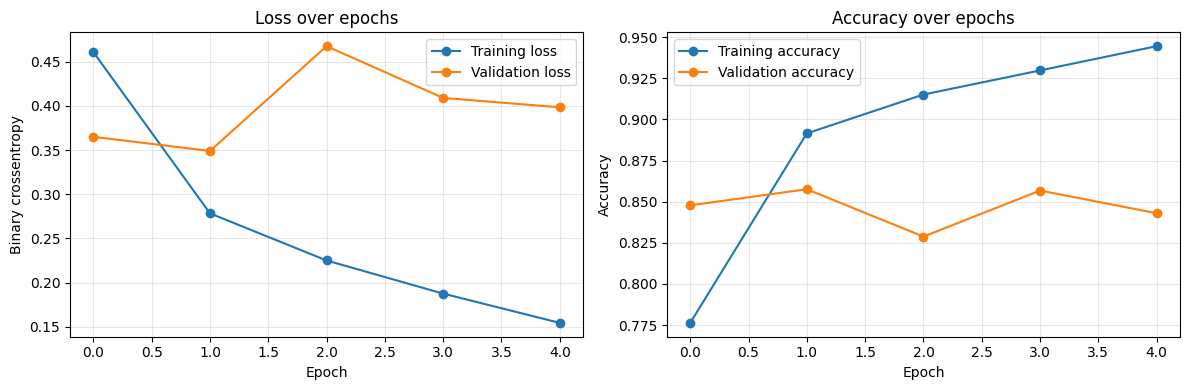

In [6]:
# Evaluate on the unseen test set
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("The lab handout gives approximately 86–88% as an expected result; actual results can vary.")

# Plot loss and accuracy for training and validation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("Accuracy over epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Task 5 — Predict sentiment for new text

**Important preprocessing detail:** IMDB reserves index `0` for padding, `1` for the start token and `2` for unknown / out-of-vocabulary words. Known word IDs are shifted by `+3`. Words outside the top 10,000 are mapped to the unknown token (`2`).

We use Keras' text tokenizer helper to split punctuation consistently rather than simply splitting on spaces.


In [7]:
word_index = imdb.get_word_index()

def encode_review(review):
    # Tokenize similarly to the IMDB dataset preprocessing.
    words = text_to_word_sequence(review)

    # IMDB sequence format starts with token 1.
    encoded = [1]
    for word in words:
        original_index = word_index.get(word)

        if original_index is None:
            encoded.append(2)  # unknown word
        else:
            imdb_index = original_index + 3
            # Keep only the vocabulary range used by the trained model.
            encoded.append(imdb_index if imdb_index < num_words else 2)

    return pad_sequences(
        [encoded],
        maxlen=maxlen,
        padding="pre",
        truncating="pre"
    )

def predict_sentiment(review):
    padded_review = encode_review(review)
    probability_positive = float(model.predict(padded_review, verbose=0)[0][0])

    sentiment = "Positive" if probability_positive >= 0.5 else "Negative"
    return sentiment, probability_positive

examples = [
    "This film was absolutely wonderful and moving",
    "A boring dull waste of time"
]

for review in examples:
    sentiment, probability = predict_sentiment(review)
    print(f"{sentiment:8s} | positive probability = {probability:.3f} | {review}")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive | positive probability = 0.937 | This film was absolutely wonderful and moving
Negative | positive probability = 0.010 | A boring dull waste of time


## Task 6 — Short answers / viva preparation

1. **Why pad every review to the same length?**  
   Neural networks process batches as rectangular arrays. Padding makes every review 200 tokens long.

2. **What does the Embedding layer do?**  
   It maps each integer word ID to a trainable dense vector of 128 numbers. Similar words can learn similar representations.

3. **Why `return_sequences=False`?**  
   The task needs one final summary vector for the whole review, not an output at every word position.

4. **Why sigmoid + binary crossentropy?**  
   There are only two classes and one output neuron. Sigmoid gives a probability from 0 to 1; binary crossentropy is the matching loss.

5. **What does rising validation loss while training loss falls indicate?**  
   It can indicate overfitting: the model is fitting the training reviews but generalising less well to unseen reviews. Dropout helps reduce overfitting; early stopping can also stop training when validation performance stops improving.

6. **Why is the Bidirectional LSTM output 128-dimensional?**  
   It concatenates 64 features from the forward LSTM and 64 from the backward LSTM: `64 + 64 = 128`.

7. **What does `batch_size=64` mean?**  
   The model processes 64 reviews before performing a weight update.

8. **What does `epochs=5` mean?**  
   The model makes five complete passes through the training data.

9. **What is the purpose of the validation set?**  
   It monitors generalisation during training and helps identify overfitting. The test set is reserved for final evaluation.

10. **What accuracy does the lab handout say to expect?**  
    Approximately 86–88%; the exact value can vary with the run and software/hardware version.
